In [1]:
import matplotlib.pyplot as plt
import numpy as np
import numpy.ma as ma
import pandas as pd
import scipy as sp
import seaborn as sns
from scipy import stats
from scipy.stats import bootstrap
from scipy.optimize import curve_fit
from scipy.optimize import fsolve
from scipy.optimize import approx_fprime
from sklearn.metrics import r2_score
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Suppress warnings (temporary)
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=DeprecationWarning)

# Set some defaults
# custom_cmap = LinearSegmentedColormap.from_list("custom", ["#F1F744", "#D49BFF"])
sns.set_theme(context="paper", font_scale=1.2)
sns.set_style("ticks")
plt.rcParams["mathtext.default"] = "regular"
plt.rc("axes.spines", top=False, right=False)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
# Reading in processed data from combine_dataframes nb
test = pd.read_csv("data/processed-adapt.csv")
# Including last trial of baseline to compute ALL adaptation measures
test = test.loc[test["TN"] >= 100, :].reset_index(drop=True)


In [3]:
def compute_betas(df: pd.DataFrame, rot_range: int, bivariate=True):

    df_filt = df[df["rotation"].between(-rot_range, rot_range, inclusive='both')]

    # df_filt = df_filt[np.abs(df_filt["adaptation"]) < 15]

    # Prepare data for regression
    data = pd.DataFrame({
        'ege': df_filt["rotation"], 
        'ige': df_filt["theta_maxradv_clean"],
        'adapt': df_filt["adaptation"]
    })
    
    if bivariate:
        # Run OLS regression 
        model = ols("adapt ~ ege + ige - 1", data).fit()
        beta_ege = model.params.get("ege", np.nan)
        beta_ige = model.params.get("ige", np.nan)
        return beta_ege, beta_ige
    else:
        model = ols("adapt ~ ege", data).fit()
        beta_ege = model.params.get("ege", np.nan)
        return beta_ege

    
def piecewise_linear_2bp(x, a, b, c, e, x0, x1):
    '''
    x: input data
    a: slope from -10 to -6
    b: bias from -10 to -6
    c: slope from -6 to +6
    d: bias from -6 to +6
    e: slope from +6 to +10
    f: bias from +6 to +10
    '''
    # Ensure continuity across both breakpoints
    d = a * x0 + b - c * x0
    f = c * x1 + d - e * x1
    return np.piecewise(
        x,
        [x < x0, (x >= x0) & (x < x1), x >= x1],
        [lambda x: a * x + b,  
        lambda x: c * x + d,
        lambda x: e * x + f]
    )
    
def fit_piecewise_with_ci(df, subject_id, xcol="rotation", ycol="adaptation", 
                          bp1=6, bp2=-6, n_points=300, alpha=0.05):

    x = np.array(df[xcol])
    y = np.array(df[ycol])

    # Remove NaN or Inf
    mask = ~np.isnan(x) & ~np.isnan(y)
    x_clean, y_clean = x[mask], y[mask]

    # Fit
    popt, pcov = curve_fit(
        lambda x, a, b, c, e: piecewise_linear_2bp(x, a, b, c, e, x0=bp2, x1=bp1),
        x_clean, y_clean
    )

    # Fit line
    x_fit = np.linspace(min(x_clean), max(x_clean), n_points)
    y_fit = piecewise_linear_2bp(x_fit, *popt, x0=bp2, x1=bp1)

    # Jacobian for variance propagation
    eps = np.sqrt(np.finfo(float).eps)
    jac = np.array([
        approx_fprime(popt, 
                      lambda p: piecewise_linear_2bp(np.array([xx]), *p, x0=bp2, x1=bp1)[0], 
                      eps)
        for xx in x_fit
    ])
    var_pred = np.sum(jac @ pcov * jac, axis=1)
    std_pred = np.sqrt(var_pred)

    # Confidence intervals
    z = 1.96  # ~95% for large df
    ci_upper = y_fit + z * std_pred
    ci_lower = y_fit - z * std_pred

    return x_fit, y_fit, ci_lower, ci_upper, popt, pcov

In [4]:
# Count number of outliers per participant
num_outliers = test.groupby("SN")["x_f_outlier"].sum()
print(num_outliers)

print(f"Total percent of outlier trials: {num_outliers.sum() / (1540 * 16)}")

# Print proportion of trials removed
pct_outliers = num_outliers / test["TN"].max()
print(pct_outliers)

# Print stats
print(pct_outliers.min(), pct_outliers.max(), pct_outliers.mean())

SN
1       5
2       4
3     114
4      10
5       5
6       5
7       5
8       2
9      10
10      4
11      6
12      9
13      3
14      8
15     11
16      4
Name: x_f_outlier, dtype: int64
Total percent of outlier trials: 0.008319805194805194
SN
1     0.003049
2     0.002439
3     0.069512
4     0.006098
5     0.003049
6     0.003049
7     0.003049
8     0.001220
9     0.006098
10    0.002439
11    0.003659
12    0.005488
13    0.001829
14    0.004878
15    0.006707
16    0.002439
Name: x_f_outlier, dtype: float64
0.0012195121951219512 0.06951219512195123 0.0078125


The slope for EGE is -0.285; IGE is -0.158.


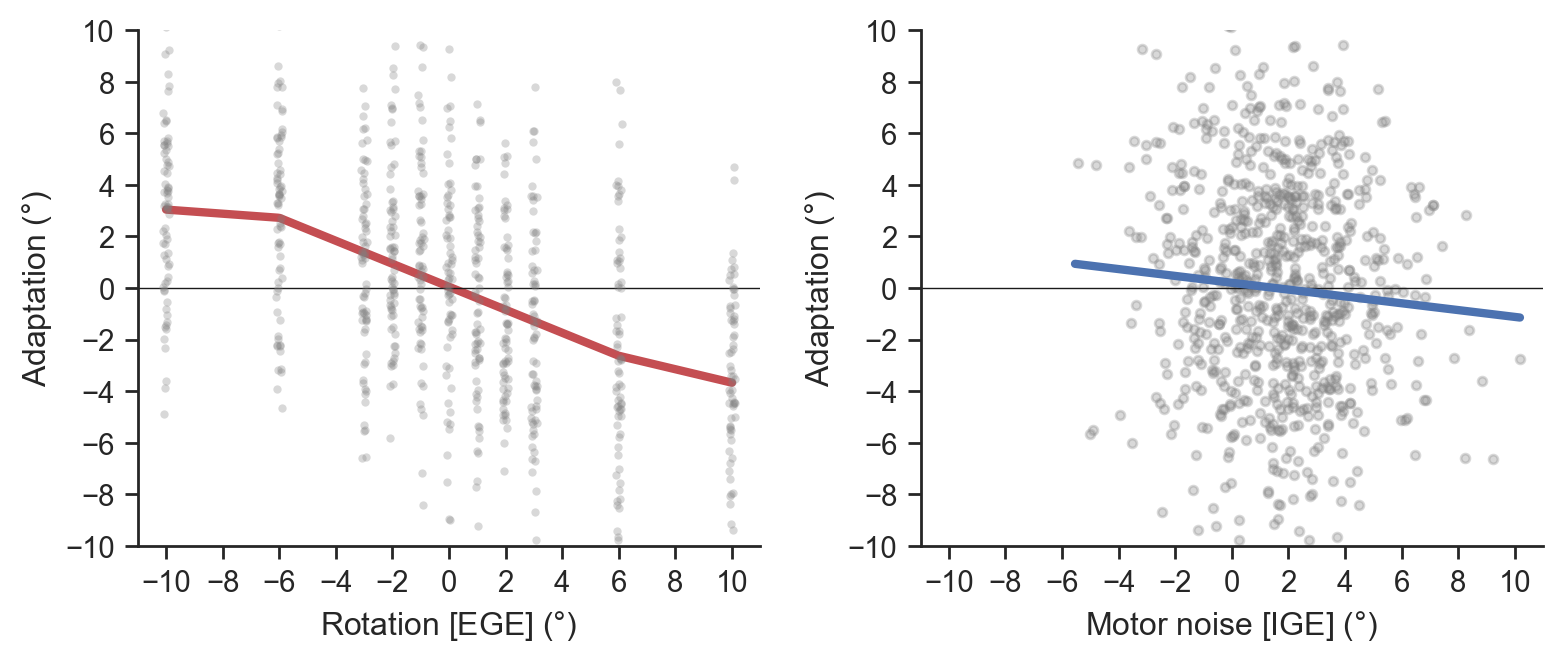

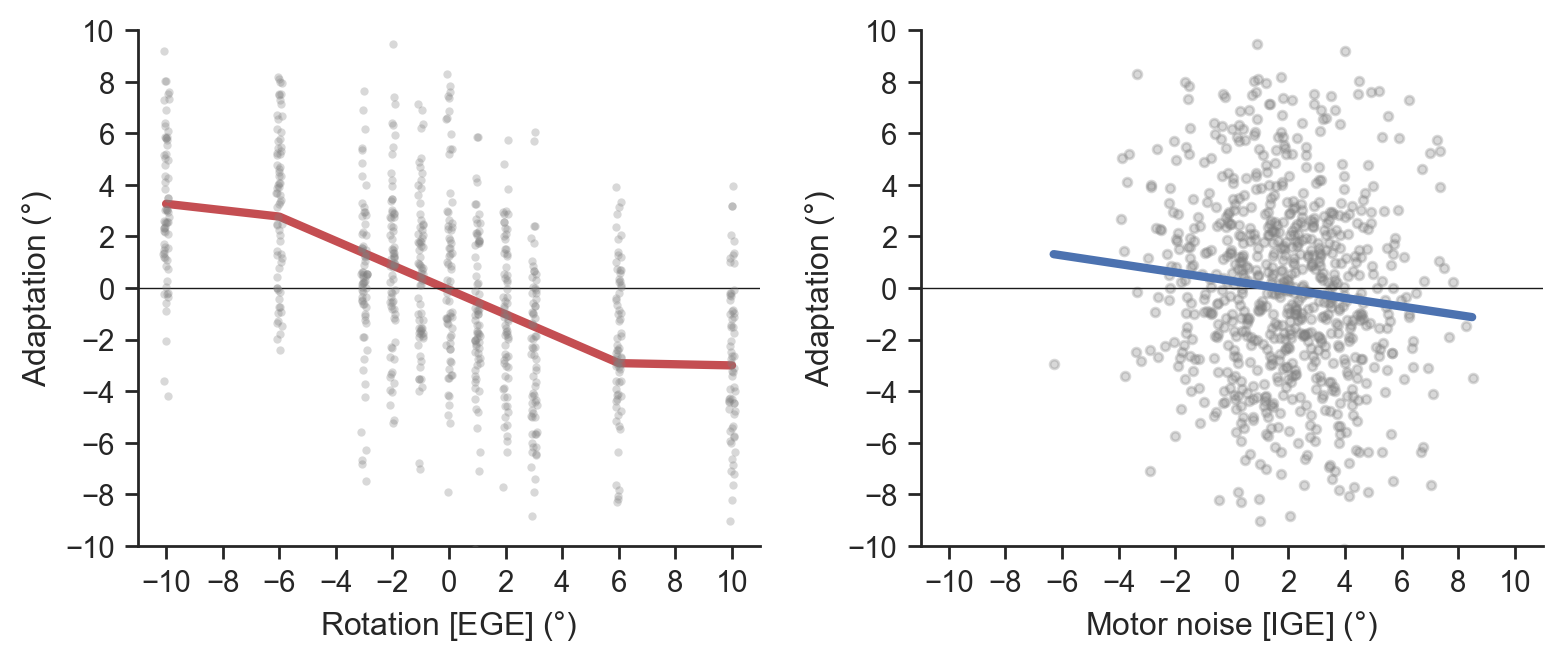

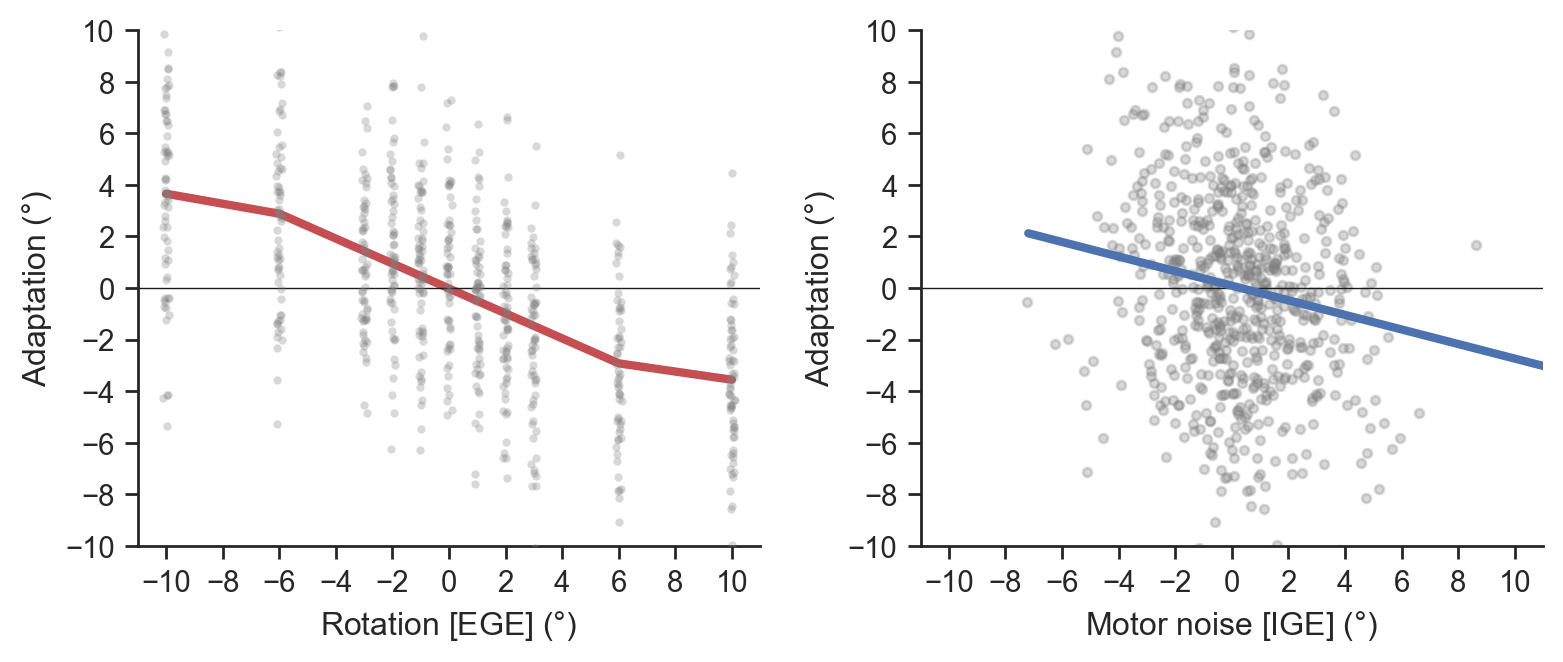

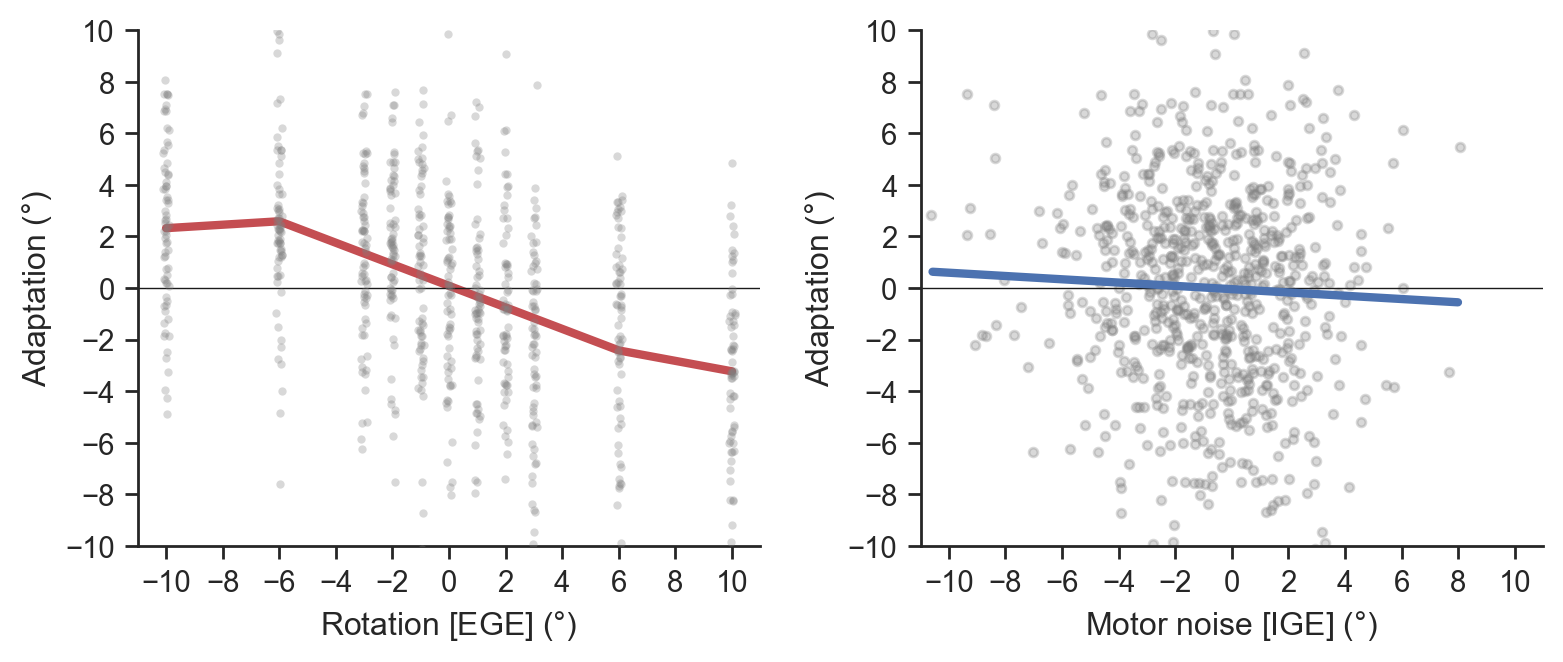

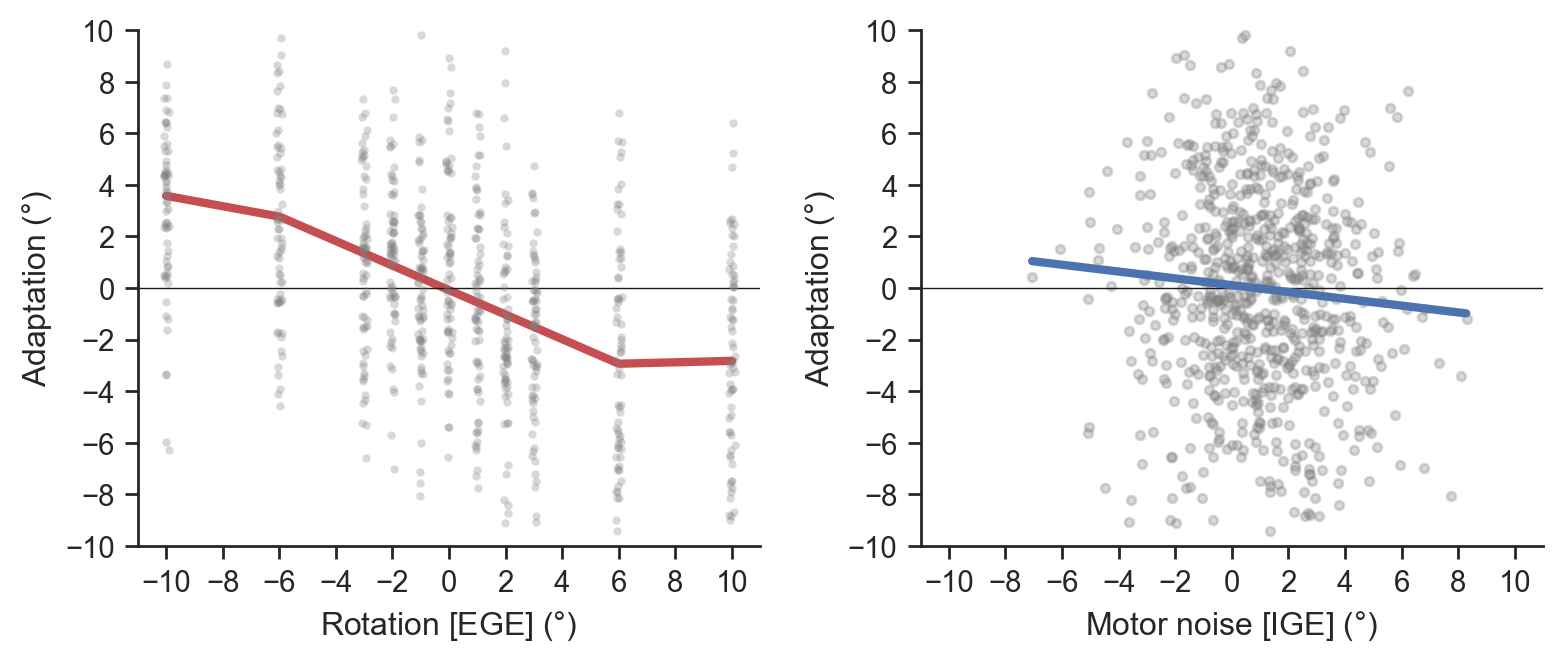

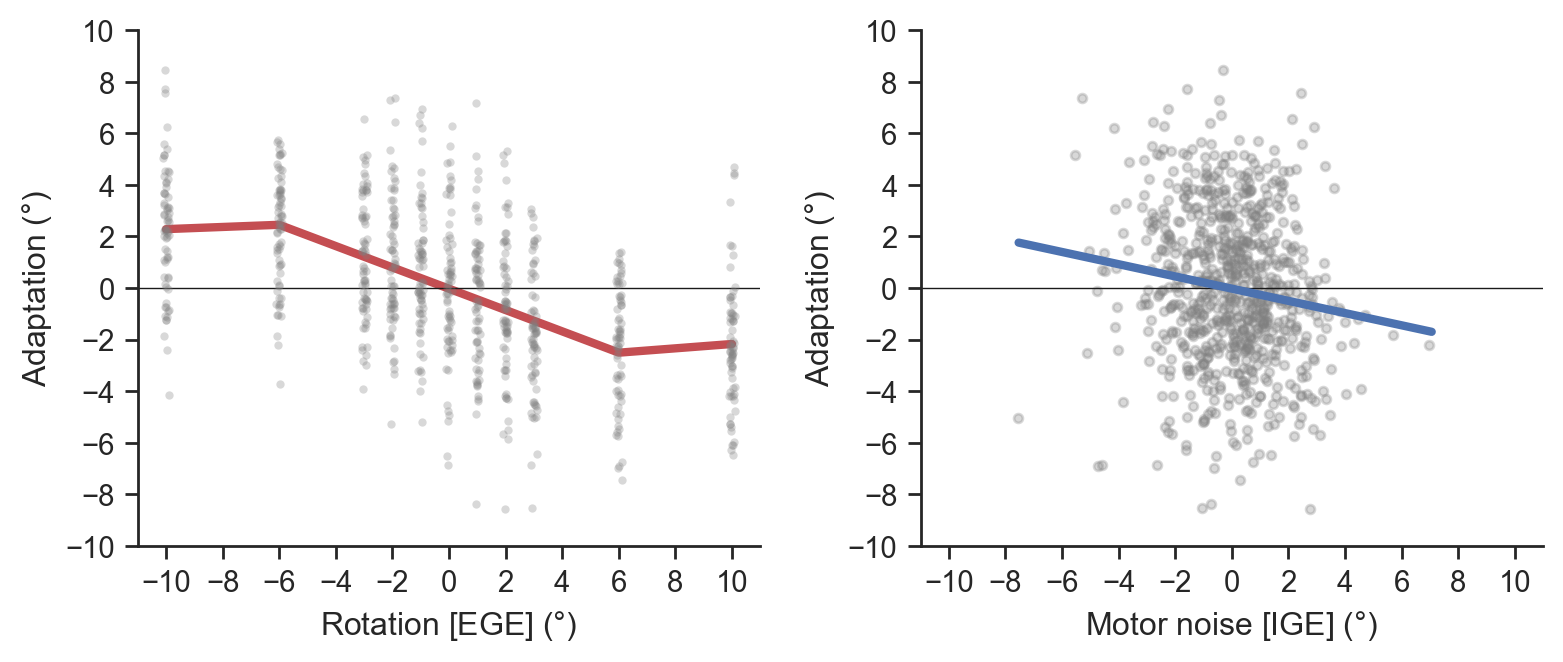

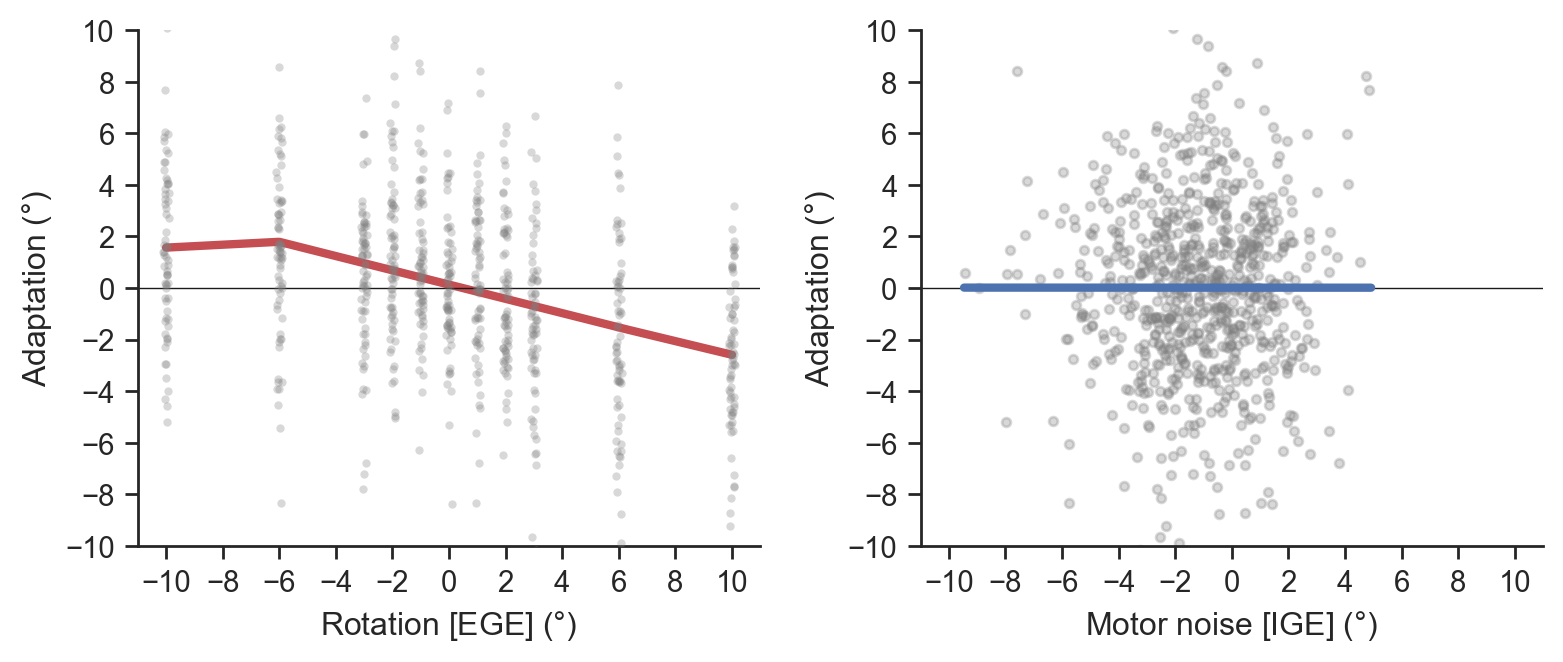

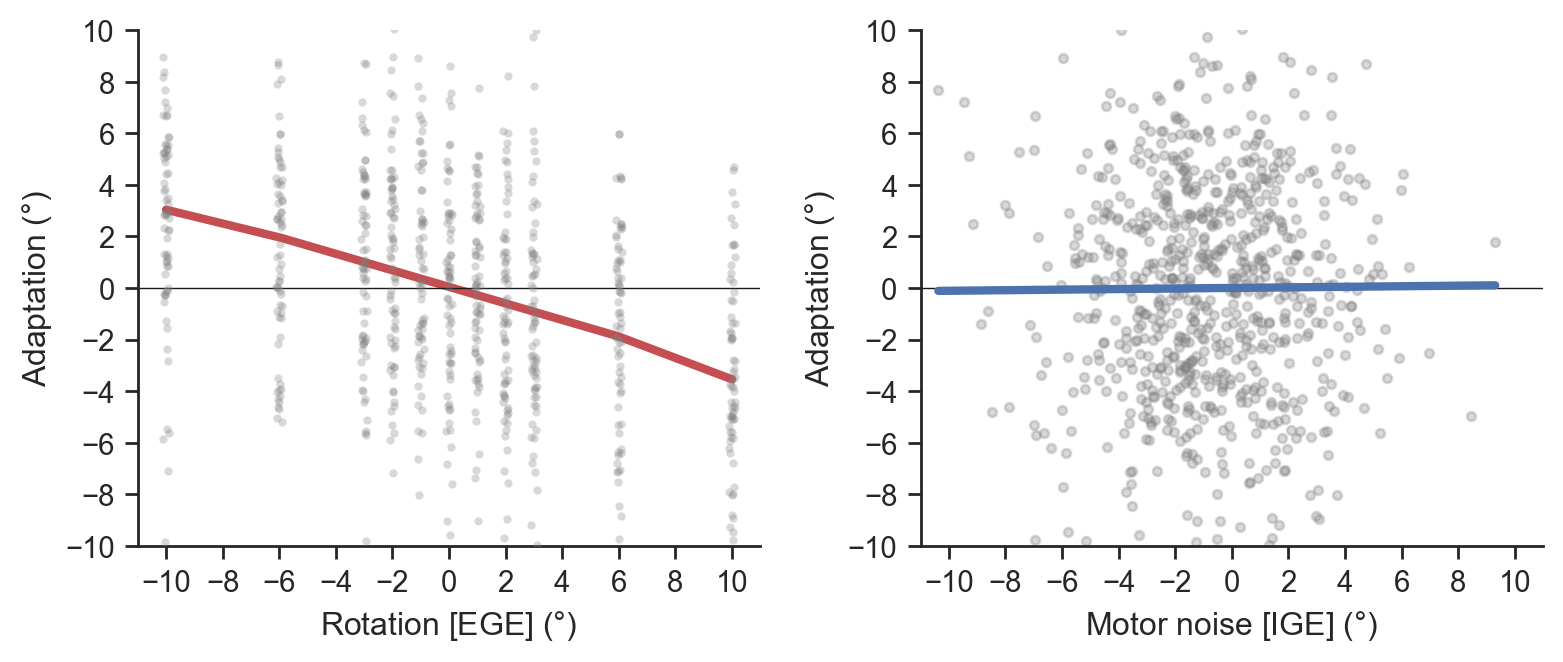

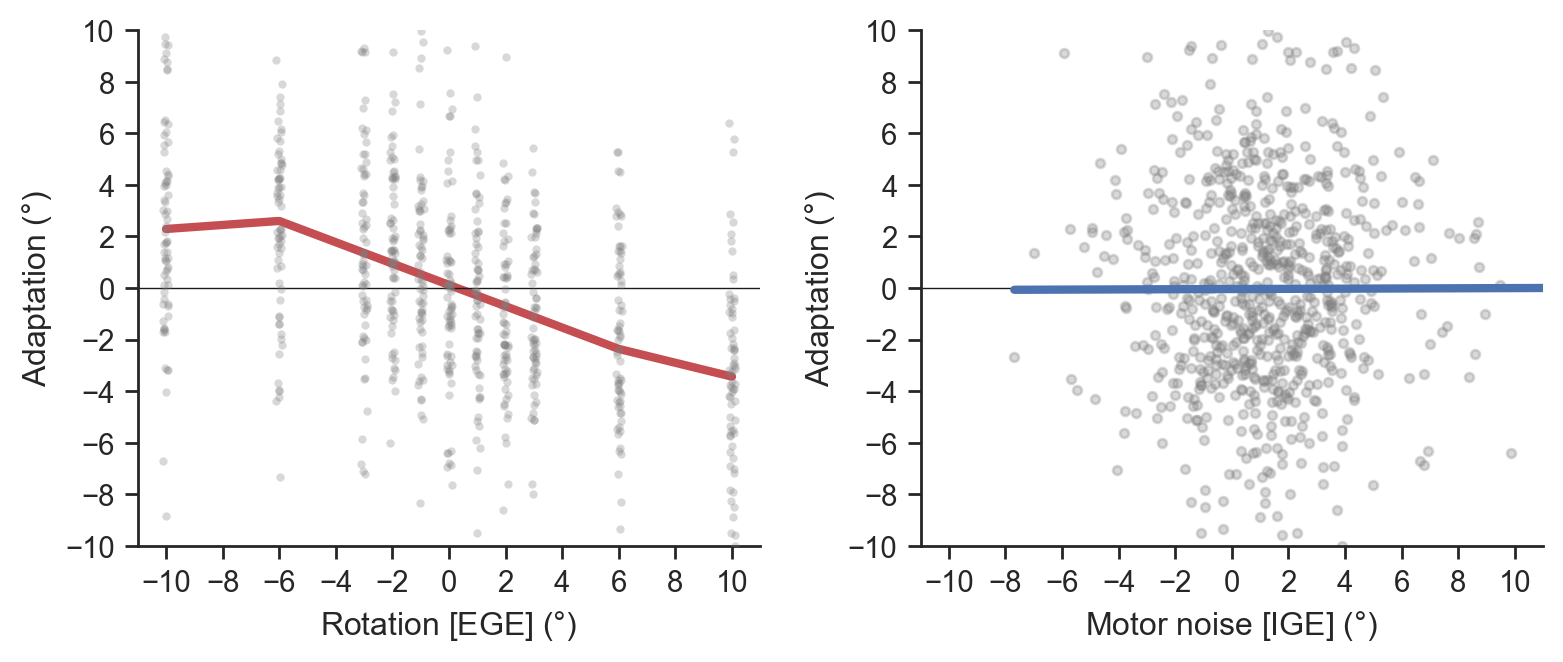

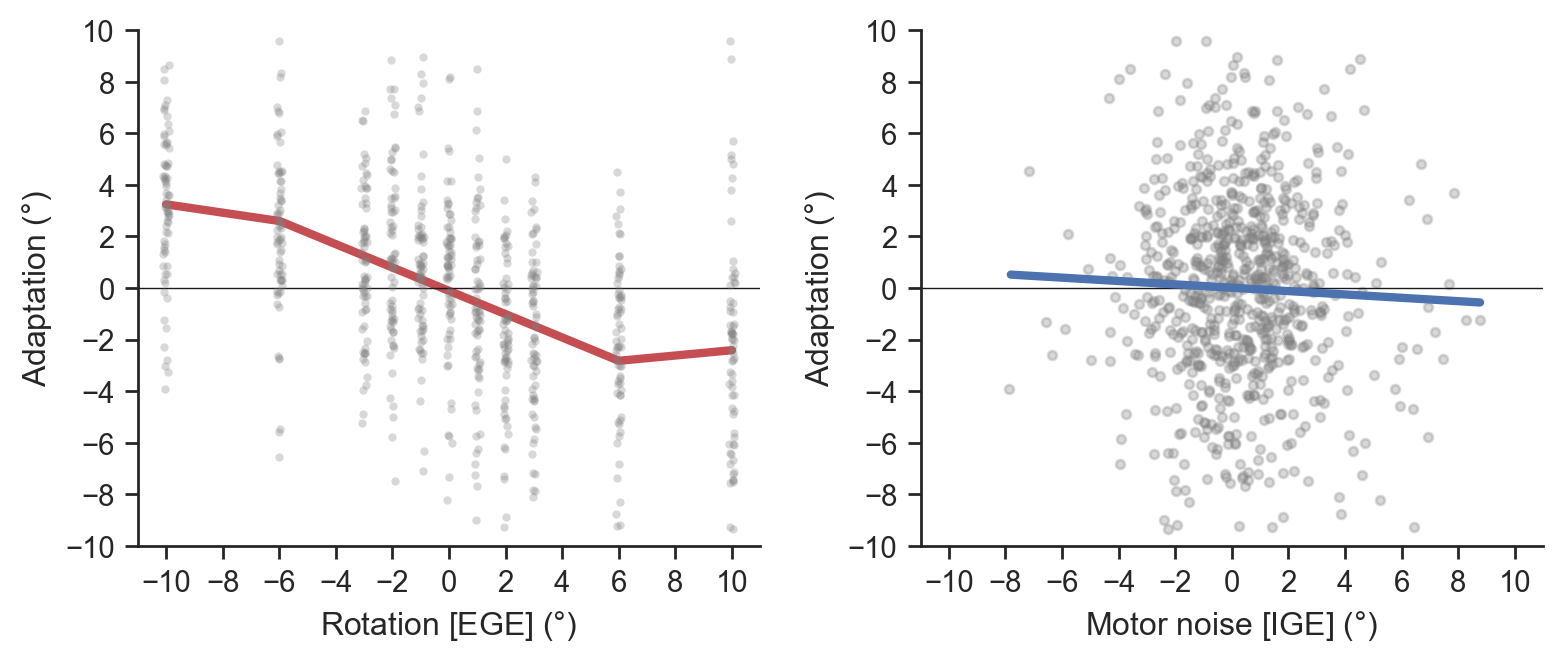

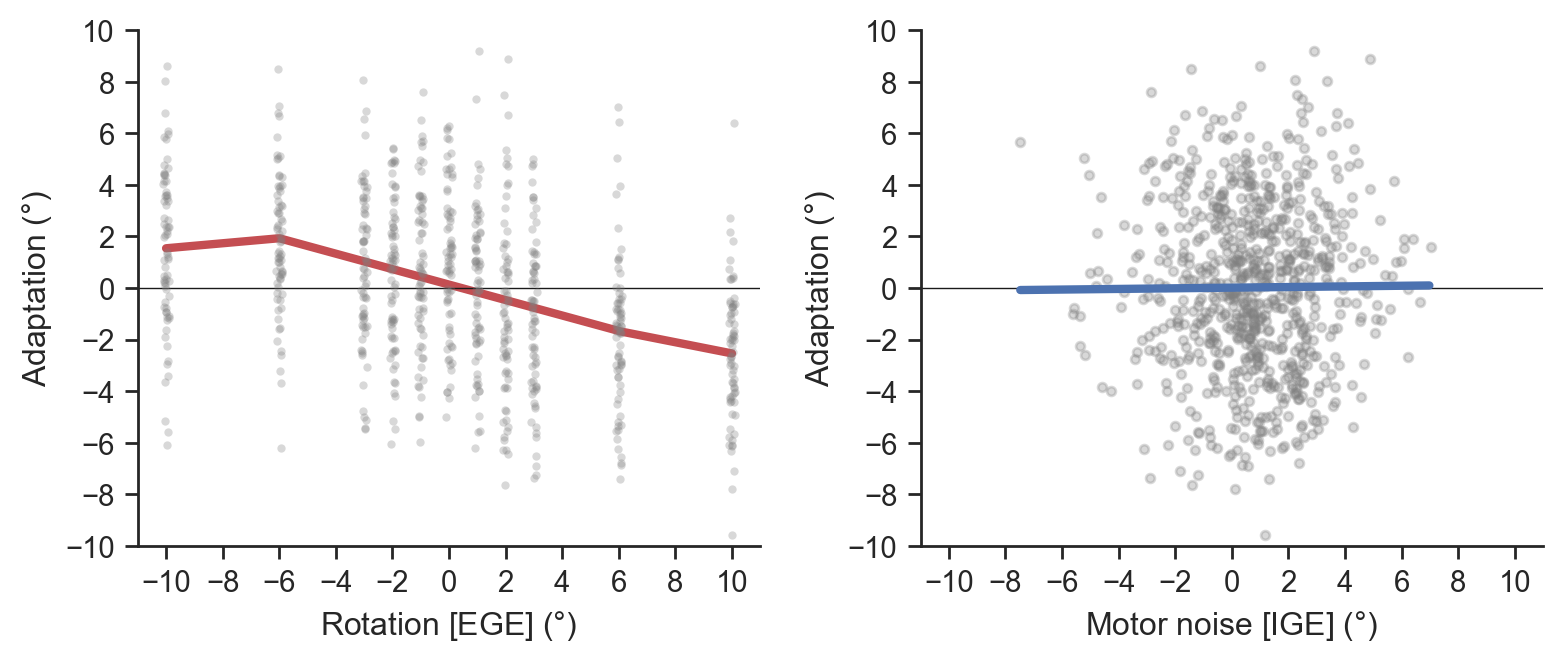

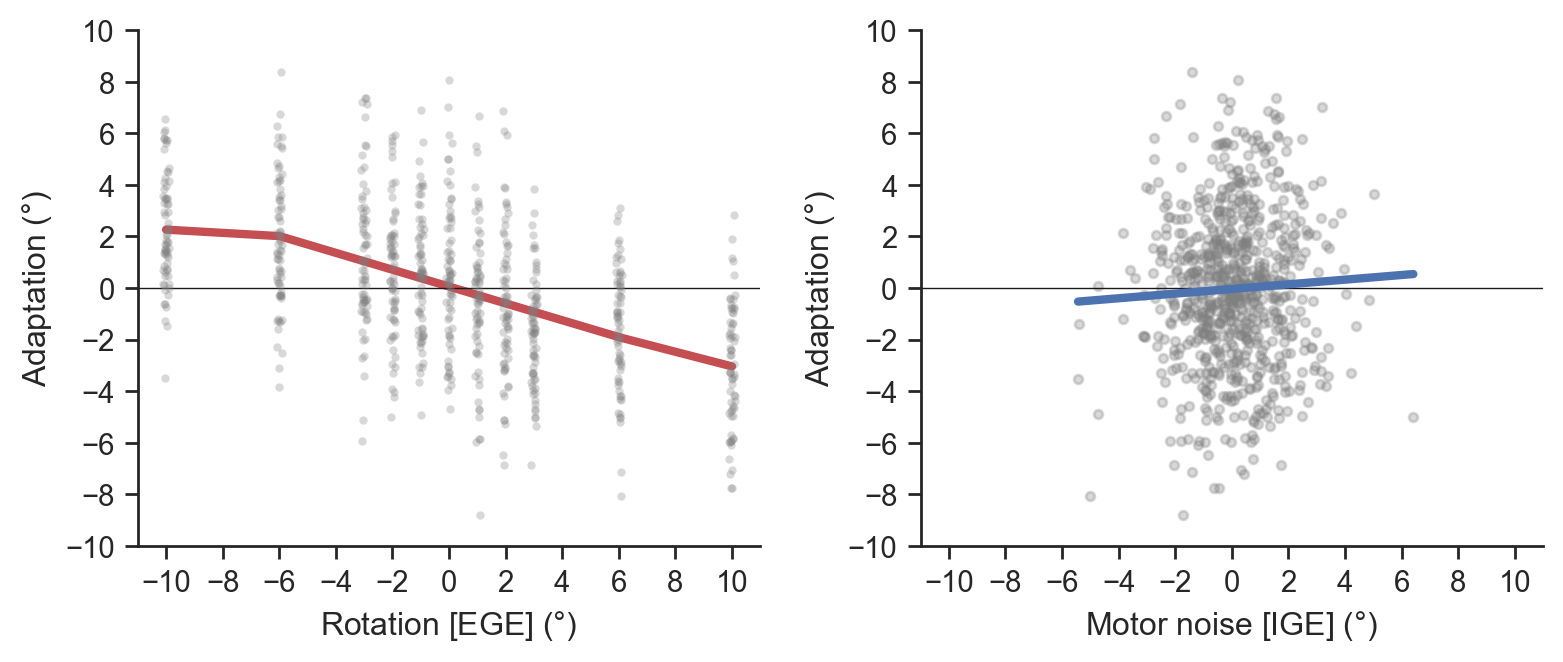

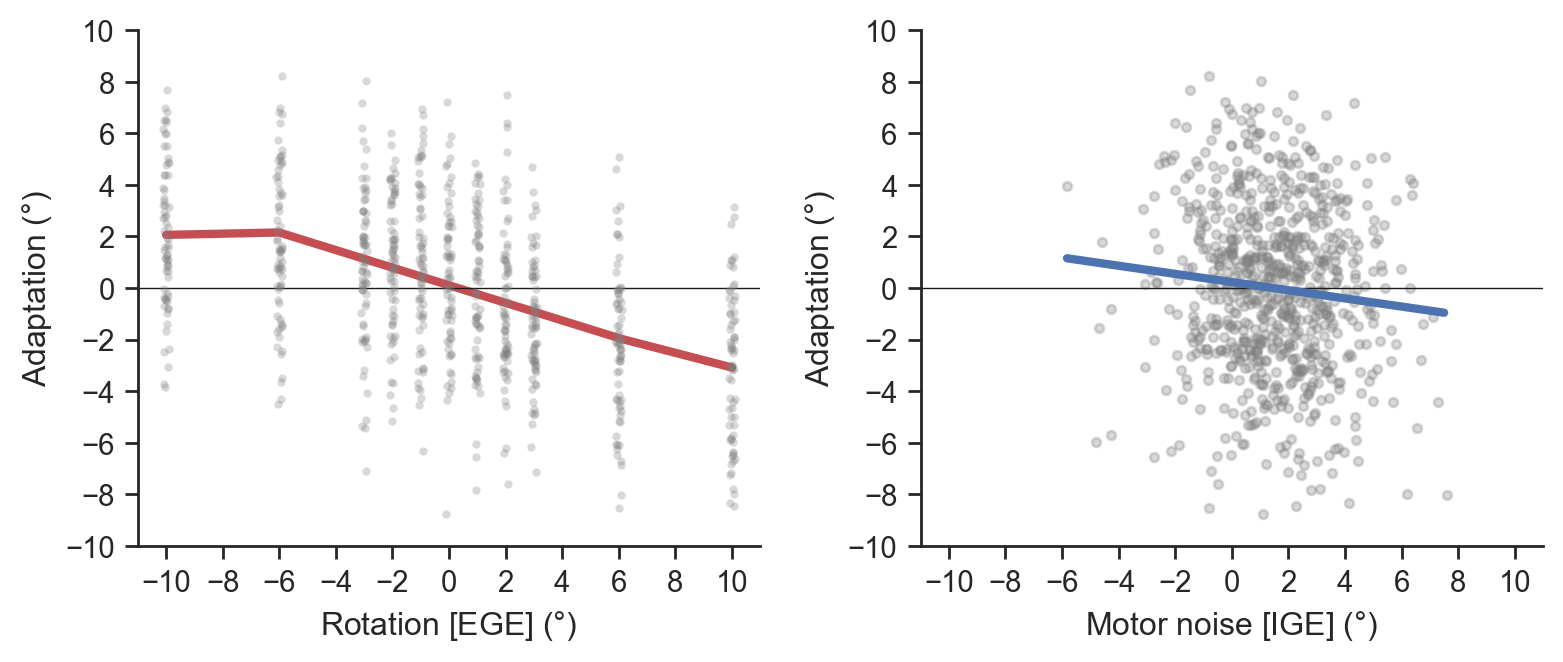

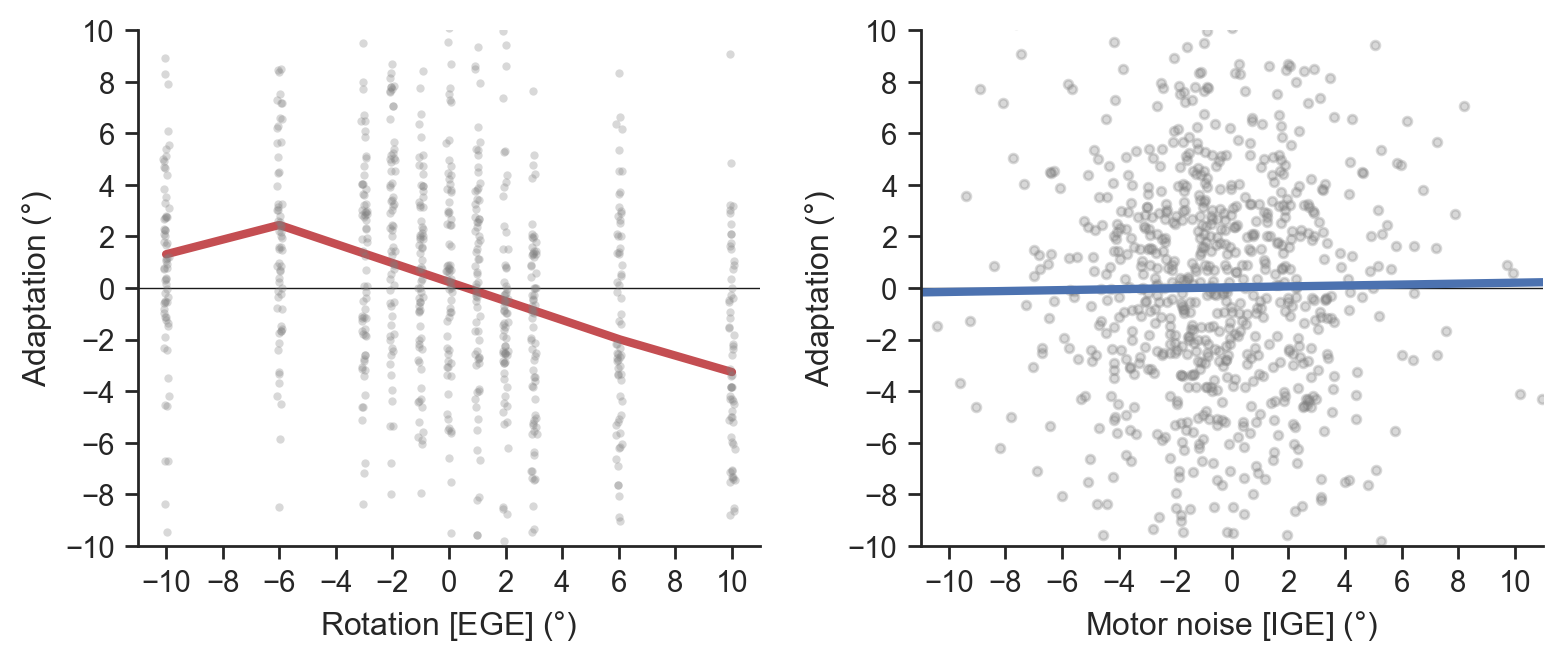

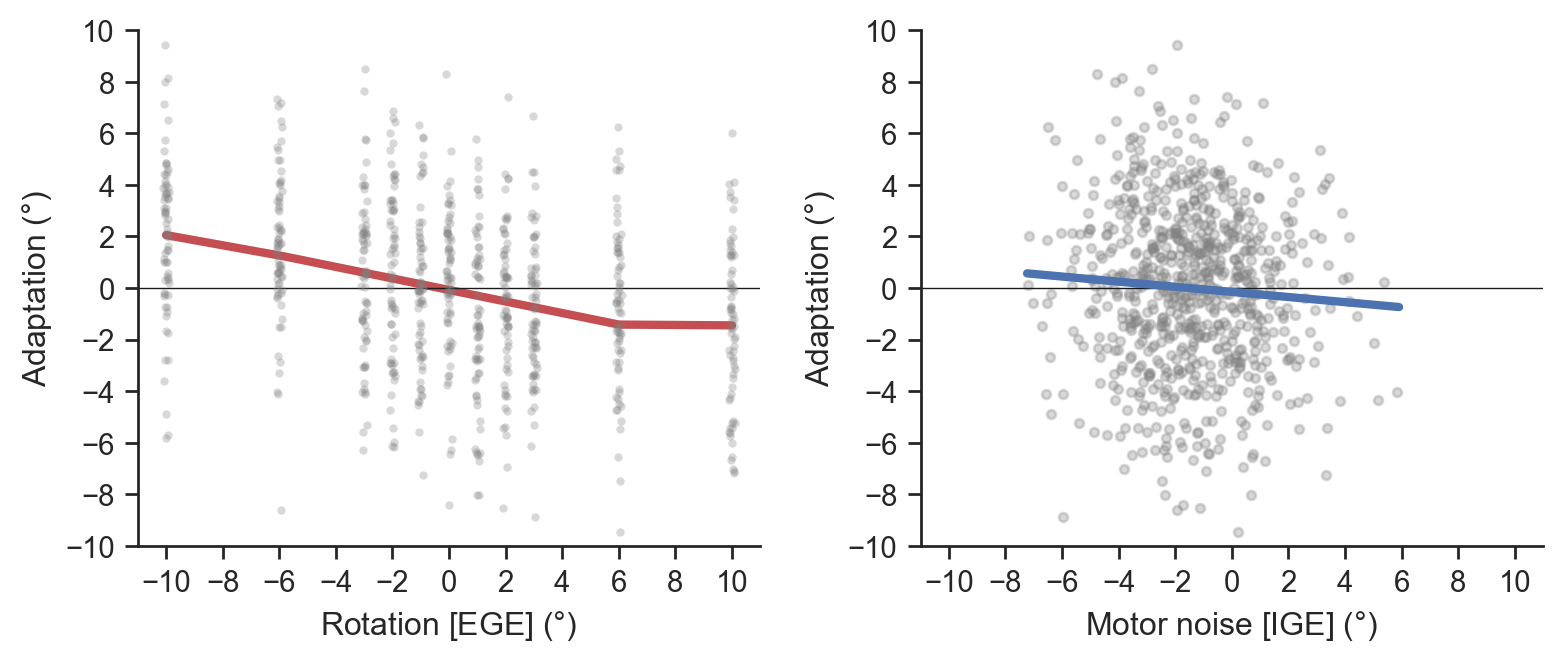

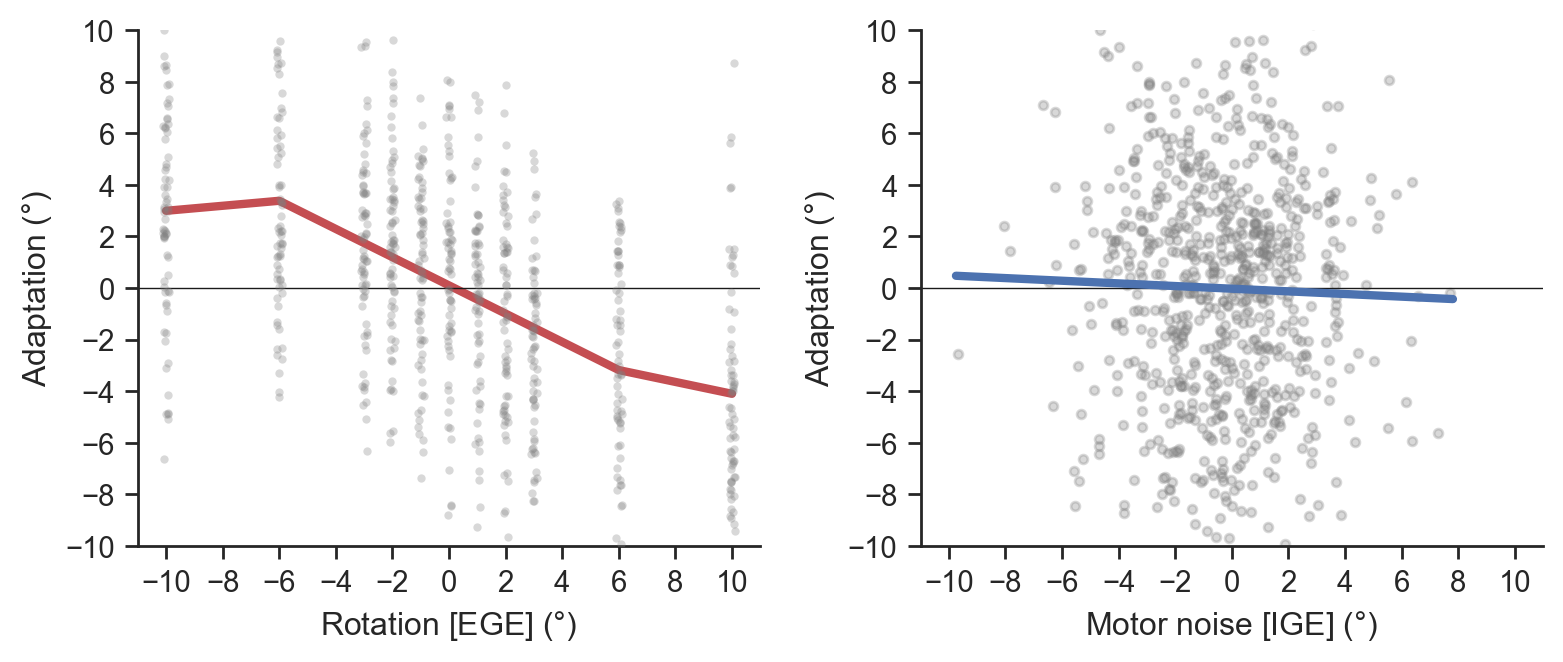

In [5]:
# Choose whether to visualize all data or only adaptation trials preceded by no fb
truncate = False

adapt_rotation = pd.DataFrame()
vmr_all = pd.DataFrame()
sigma_motor_bsl = []
sigma_motor_train = []
sigma_v_train = []
beta_rotation_ege = np.zeros(len(test["id"].unique()))
beta_rotation_ige = np.zeros(len(test["id"].unique()))
beta_ege_1ege_bi = np.zeros(len(test["id"].unique()))
beta_ige_1ege_bi = np.zeros(len(test["id"].unique()))
beta_ege_1ege_uni = np.zeros(len(test["id"].unique()))
beta_ige_1ige_uni = np.zeros(len(test["id"].unique()))
beta_ege_6ege_uni = np.zeros(len(test["id"].unique()))
beta_ige_6ege_uni = np.zeros(len(test["id"].unique()))
beta_ege_6ege_bi = np.zeros(len(test["id"].unique()))
beta_ige_6ege_bi = np.zeros(len(test["id"].unique()))
beta_ege_all_uni = np.zeros(len(test["id"].unique()))
beta_ext = np.zeros(len(test["id"].unique()))
n_1ige = np.zeros(len(test["id"].unique()))
sigma_motor_train = []

for k, s in enumerate(test["id"].unique()):

    # Testing another way to compute adaptation
    testsubj = test[test["id"] == s].reset_index(drop=True)
    reach_postpert = testsubj["x_f_clean"].shift(-1)
    reach_prepert = testsubj["x_f_clean"].shift(1)
    testsubj["adaptation"] = reach_postpert - reach_prepert
    testsubj.loc[testsubj["pert_trial"] == False, "adaptation"] = None
    df_vmr = testsubj.loc[testsubj["pert_trial"] == True, :].reset_index(drop=True)
    df_vmr["rotation"] = df_vmr["delta_xv"]
    df_vmr["theta_maxradv_clean"] = df_vmr["x_f_clean"]
    
    vmr = df_vmr

    # Compute motor SD during perturbation block (exclude last bsl trial)
    sigma_motor_train.append(testsubj.loc[1:, "x_f_clean"].std())

    # Concatenate individual subject data frames
    adapt_rotation = pd.concat([adapt_rotation, df_vmr], ignore_index=True)
    
    # Fit EGE-adaptation data with breakpoint regression
    x_fit, y_fit, ci_lower, ci_upper, popt, pcov = fit_piecewise_with_ci(df_vmr, df_vmr["SN"], xcol="rotation", ycol="adaptation", 
                                                                        bp1=6, bp2=-6, n_points=300, alpha=0.05)
    
    # Plot data for adapt vs vmr-ege
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 3.5))
    sns.stripplot(data=df_vmr, x="rotation", y="adaptation", color="gray", alpha=0.3, s=3, native_scale=True, ax=ax1)
    ax1.plot(x_fit, y_fit, c="r", linewidth=3)
    ax1.axhline(0, c="k", linewidth=0.5)
    ax2.axhline(0, c="k", linewidth=0.5)
    ax1.set(xticks=np.arange(-10, 10.1, 2), yticks=np.arange(-10, 10.1, 2), xlabel="Rotation [EGE] ($\degree$)", 
            xlim=(-11, 11), ylim=(-10, 10), ylabel="Adaptation ($\degree$)")
    sns.despine()
    
    # Plot data for adapt vs ige
    sns.regplot(data=df_vmr, x="theta_maxradv_clean", y="adaptation", x_jitter=0.1, 
               line_kws=dict(linewidth=3), scatter_kws=dict(alpha=0.3, color='gray', s=10), ci=0, ax=ax2)
    ax2.set(xticks=np.arange(-10, 10.1, 2), yticks=np.arange(-10, 10.1, 2), xlabel="Motor noise [IGE] ($\degree$)", 
        xlim=(-11, 11), ylim=(-10, 10), ylabel="Adaptation ($\degree$)")
    sns.despine()
    plt.tight_layout()
    
    # Save individual data fig and print out linear regression results
    if k == 12:
        # Get rid of all rows with NaNs in either adaptation or hand cols
        df_vmr = df_vmr.dropna(subset=["adaptation", "theta_maxradv_clean"])
        
        # fig.savefig("images/s13.pdf", dpi=300)
        slope_ege, _, _, _, _ = stats.linregress(x=df_vmr["rotation"], y=df_vmr["adaptation"])
        slope_ige, _, _, _, _ = stats.linregress(x=df_vmr["theta_maxradv_clean"], y=df_vmr["adaptation"])
        print(f"The slope for EGE is {slope_ege:.3f}; IGE is {slope_ige:.3f}.")
   
    # Some simple frequentist statistics
    data1 = pd.DataFrame({
        'ege': vmr["rotation"], 
        'ige': vmr["theta_maxradv_clean"],
        'adapt': vmr["adaptation"]
    })
    
    # Fit bivariate regression model to all data
    model_vmr = ols("adapt ~ ege + ige - 1", data1).fit()
    beta_rotation_ege[k] = model_vmr._results.params[0]
    beta_rotation_ige[k] = model_vmr._results.params[1]

    # Fit univariate regression to all data
    beta_ege_all_uni[k] = compute_betas(vmr, 10, bivariate=False)
    
    # Fit univariate regression to -6:6 data only
    six_deg_idx = np.abs(data1["ege"]) <= 6
    six_deg = data1.loc[six_deg_idx, :]
    beta_ege_6ege_uni[k] = compute_betas(vmr, 6, bivariate=False)

    # Fit bivariate regression to -6:6 data only
    beta_ege_6ege_bi[k], beta_ige_6ege_bi[k] = compute_betas(vmr, 6, bivariate=True)
    
    # Fit bivariate regression to EGE -1:+1 data only
    one_deg_idx = np.abs(data1["ege"]) <= 1
    one_deg = data1.loc[one_deg_idx, :]
    model = ols("adapt ~ ege + ige - 1", one_deg).fit()
    beta_ege_1ege_bi[k] = model._results.params[0]
    beta_ige_1ege_bi[k] = model._results.params[1]

    # Fit univariate regression to EGE -1:+1 data only
    beta_ege_1ege_uni[k] = compute_betas(vmr, 1, bivariate=False)
    
    # Fit univariate regression to -1:+1 IGE data only
    one_ige_idx = np.abs(data1["ige"]) <= 1
    n_1ige[k] = one_ige_idx.sum()
    one_ige = data1.loc[one_ige_idx, :]
    model = ols("adapt ~ ige - 1", one_ige).fit()
    beta_ige_1ige_uni[k] = model._results.params[0]

# Save slopes (reverse sign for ease of comparison)
slopes = pd.DataFrame({"beta_ege_6ege_uni": beta_ege_6ege_uni * -1, 
                       "beta_ege_6ege_bi": beta_ege_6ege_bi * -1,
                       "beta_ige_6ege_bi": beta_ige_6ege_bi * -1,
                       "beta_ege_1ege_bi": beta_ege_1ege_bi * -1, 
                       "beta_ige_1ege_bi": beta_ige_1ege_bi * -1})
# slopes.to_csv("slopes.csv", index=False)

fig.savefig("../figs/s16_adapt.pdf", dpi=300)

In [6]:
# Process data to create 5x5 IGE/EGE plots. Binning based on IGE.
adapt_rotation["ige_quintile"] = adapt_rotation.groupby(["SN", "rotation"])["theta_maxradv_clean"].transform(
    lambda x: pd.qcut(x, 5, labels=range(1, 6)))

rotation_binned = adapt_rotation.groupby(["SN", "rotation", "ige_quintile"])[["theta_maxradv_clean", "adaptation"]].mean().reset_index()

In [7]:
# For each individual, regress 25 bins onto IGE/EGE (include col of IGE values)
beta_binned_vmr = np.zeros(16)
beta_binned_vmr_ige = np.zeros(16)

for idx, val in enumerate(rotation_binned["SN"].unique()):
    subj_rot = rotation_binned.loc[rotation_binned["SN"] == val, :]
    
    model_vmr = ols("adaptation ~ rotation - 1", subj_rot).fit()
    model_vmr_ige = ols("adaptation ~ theta_maxradv_clean - 1", subj_rot).fit()

    beta_binned_vmr[idx] = model_vmr._results.params
    beta_binned_vmr_ige[idx] = model_vmr_ige._results.params
   
beta_binned_vmr = (beta_binned_vmr,)
beta_binned_vmr_ige = (beta_binned_vmr_ige,)

res_vmr = bootstrap(beta_binned_vmr, np.mean, method="percentile").confidence_interval
res_vmr_ige = bootstrap(beta_binned_vmr_ige, np.mean, method="percentile").confidence_interval

print(f"95\% CI for VMR-EGE: {res_vmr}")
print(f"95\% CI for VMR-IGE: {res_vmr_ige}")


95\% CI for VMR-EGE: ConfidenceInterval(low=np.float64(-0.3449139903504656), high=np.float64(-0.2838818126056871))
95\% CI for VMR-IGE: ConfidenceInterval(low=np.float64(-0.0964490065673829), high=np.float64(-0.006846320149352487))


In [8]:
# Create data frames for population-averaged Adapt vs IGE/EGE. "as_index"
# argument flattens dataframe, instead of keeping hierarchical indexing
popn_rotation = rotation_binned.groupby(
    ["rotation", "ige_quintile"], as_index=False).mean().drop(columns="SN")  

popn_rotation

,rotation,ige_quintile,theta_maxradv_clean,adaptation
0,-10,1,-2.997965,2.678089
1,-10,2,-0.977363,2.568013
2,-10,3,0.100243,2.361741
3,-10,4,1.261204,2.670304
4,-10,5,3.357865,2.346331
5,-6,1,-2.920962,2.580435
6,-6,2,-0.912390,2.335145
7,-6,3,0.270326,2.391377
8,-6,4,1.473956,2.089593
9,-6,5,3.512835,1.831395


In [9]:
# Put regression coeffs into data frame
n = len(beta_rotation_ege)
subj_num = np.linspace(1, len(beta_rotation_ege), len(beta_rotation_ege), n)
df_betas = pd.DataFrame({
    "subject":subj_num, 
    "EGE": np.repeat("EGE", n),
    "IGE": np.repeat("IGE", n),
    "beta_rotation_ege":beta_rotation_ege * -1, 
    "beta_rotation_ige":beta_rotation_ige * -1,
})

In [10]:
def plot_coeffs(ax, data, y1, y2):
    sns.pointplot(data=data, x="EGE", y=y1, ax=ax, c="r")
    sns.stripplot(data=data, x="EGE", y=y1, alpha=0.3, ax=ax, c="r")
    sns.pointplot(data=data, x="IGE", y=y2, ax=ax, c="b")
    sns.stripplot(data=data, x="IGE", y=y2, alpha=0.3, ax=ax, c="b")
    ax.axhline(linewidth=0.5, color="k")
    plt.tight_layout()
    return ax

def set_labels(fig, ax, title=None):
    ax.set(xlabel="", ylabel=r"$\beta$ (sensitivity)", title=title, ylim=(-0.25, 0.85))
    sns.despine()
    
def set_style():
    # This sets reasonable defaults for font size for
    # a figure that will go in a paper
    sns.set_theme(context="paper", font_scale=1.2)
    sns.set_style("ticks")


def plot_binned_data(binned_data, popn_data, ege_col, beta_ege_col, beta_ige_col):
    '''
    Group-level figure showing relationships between adaptation and IGE/EGE.
    '''

    # Set-up color cycles
    colors_ige = plt.get_cmap("Blues")(np.linspace(0.2, 0.8, 5))
    colors_ege = plt.get_cmap("Reds")(np.linspace(0.2, 0.8, 11))
    
    # Plot adaptive response vs IGE and EGE for rotation trials
    perts = np.unique(binned_data[ege_col])
    pert = []
    x_mean_ige = np.zeros(5)
    x_err_ige = np.zeros(5)
    y_mean_ige = np.zeros(5)
    y_err_ige = np.zeros(5)
    x_mean_ege = np.zeros(11)
    x_err_ege = np.zeros(11)
    y_mean_ege = np.zeros(11)
    y_err_ege = np.zeros(11)
    h = np.zeros(len(perts), dtype=int)
    
    fig, (ax1, ax2, ) = plt.subplots(1, 2, figsize=(8, 3.5), width_ratios=[4., 4])
    for i in range(len(perts)):
        idx = binned_data[ege_col] == perts[i]
        pert = pd.DataFrame(binned_data.loc[idx, :])
        pert["ige_mean"] = np.nan
        for j in range(5):
            idx_bin = pert["ige_quintile"] == j + 1
            temp = pert.loc[idx_bin, :]
            x_mean_ige[j] = pert.loc[idx_bin, "theta_maxradv_clean"].mean()
            x_err_ige[j] = pert.loc[idx_bin, "theta_maxradv_clean"].sem()
            y_mean_ige[j] = pert.loc[idx_bin, "adaptation"].mean()
            y_err_ige[j] = pert.loc[idx_bin, "adaptation"].sem()
            pert.loc[idx_bin, "ige_mean"] = pert.loc[idx_bin, "theta_maxradv_clean"].mean()
            # ax2.errorbar(x=x_mean_ige[j], y=y_mean_ige[j], yerr=y_err_ige[j], ecolor=colors_ege[i],
            #          **{"marker":"o", "markeredgecolor":colors_ege[i], "markerfacecolor":colors_ige[j], "linestyle":"none"}) 
            ax2.errorbar(x=x_mean_ige[j], y=y_mean_ige[j], yerr=y_err_ige[j], ecolor=colors_ege[i]) 
            ax2.set_xticks((-4, -2, 0, 2, 4))
        sns.lineplot(data=pert, x="ige_mean", y="adaptation", ax=ax2, errorbar=("ci",0),
                    color=colors_ege[i], linewidth=0.5)
        # sns.regplot(data=pert, x="ige_mean", y="adaptation", ax=ax2, ci=0, 
        #             scatter=False, scatter_kws={"color":colors_ege[i]}, 
        #             line_kws={"color":colors_ege[i], "linewidth":1})
    # Plot overall correlation and compute statistics, bootstrapped CIs
    sns.regplot(data=popn_data, x="theta_maxradv_clean", y="adaptation", ax=ax2,
                scatter=False, ci=None, line_kws={"color":"k", "linestyle":"-"})
    # ax2.plot(popn_data.groupby("ige_quintile")["theta_maxradv_clean"].mean().values, popn_data.groupby("ige_quintile")["adaptation"].mean().values, linewidth=1.5, c="k")
    ax2.axhline(linewidth=0.5, c="k")
    slope_ige, _, r_ige, p_ige, std_err_ige = stats.linregress(
        popn_data["theta_maxradv_clean"], popn_data["adaptation"])
    ax2.text(-4, 3.5, f"$r^2$={r_ige**2:.2f}", fontsize="small")
    ax2.text(-4, 3.0, f"$slope=${slope_ige:.2f}", fontsize="small")
    
    # Outer loop is for ige bins, inner loop for pert levels
    for i in range(5):
        idx = binned_data["ige_quintile"] == i + 1
        binned = pd.DataFrame(binned_data.loc[idx, :])
        for j in range(11):
            idx_ege = binned[ege_col] == perts[j]
            x_mean_ege[j] = binned.loc[idx_ege, ege_col].mean()
            x_err_ege[j] = binned.loc[idx_ege, ege_col].sem()
            y_mean_ege[j] = binned.loc[idx_ege, "adaptation"].mean()
            y_err_ege[j] = binned.loc[idx_ege, "adaptation"].sem()
            binned.loc[idx_ege, "ege_mean"] = binned.loc[idx_ege, ege_col].mean()
            # ax1.errorbar(x=x_mean_ege[j], y=y_mean_ege[j], yerr=y_err_ege[j], ecolor=colors_ege[i],
            #         **{"marker":"o", "markeredgecolor":colors_ege[j], "markerfacecolor":colors_ige[i], "linestyle":"none"})
            ax1.errorbar(x=x_mean_ege[j], y=y_mean_ege[j], yerr=y_err_ege[j], color=colors_ige[i])
            ax1.set_xticks(np.linspace(-10, 10, 11))
        sns.lineplot(data=binned, x="ege_mean", y="adaptation", ax=ax1, errorbar=("ci",0),
                    color=colors_ige[i], linewidth=0.5)
    # sns.regplot(data=popn_data, x=ege_col, y="adaptation", ax=ax1,
    #             scatter=False, ci=None, line_kws={"color":"k", "linestyle":"-", "linewidth":1.5})
    
    # ax1.plot(binned_data["rotation"].unique(), rotation_binned.groupby("rotation")["adaptation"].mean().values, linewidth=1.5, c="k")
    ax1.axhline(linewidth=0.5, c="k")
    # Plot overall correlation and compute statistics, bootstrapped CIs
    r_ege, p_ege = sp.stats.pearsonr(popn_data[ege_col], popn_rotation["adaptation"])
    slope_ege, intercept, r_ege1, p_ege, std_err_ege = stats.linregress(
        popn_data[ege_col], popn_data["adaptation"])
    # ax1.text(-4, -2.0, f"$slope=${slope_ege:.3f}", fontsize="small")
    
    # Fit EGE-adaptation data with breakpoint regression
    x_fit, y_fit, ci_lower, ci_upper, popt, pcov = fit_piecewise_with_ci(popn_rotation, 0, xcol="rotation", ycol="adaptation", 
                                                                        bp1=6, bp2=-6, n_points=300, alpha=0.05)
    
    # Compute r2 for breakpoint regression on binned data
    vals_to_find = np.unique(popn_rotation["rotation"])
    indices = np.searchsorted(x_fit, vals_to_find)
    y_hat = np.repeat(y_fit[indices], 5)  # repeat 5 times bc there are 5 vals at each pert level
    y_true = popn_rotation["adaptation"]

    n = len(y_true) # Number of observations
    p = 4          # Number of independent variables 

    # Calculate the standard R-squared
    r2 = r2_score(y_true, y_hat)

    # Calculate the adjusted R-squared
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

    print(f"R-squared: {r2}")
    print(f"Adjusted R-squared: {adjusted_r2}")
    
    # Add r2 value to plot
    ax1.text(-4, -1.5, f"$r^2$={adjusted_r2:.2f}", fontsize="small")

    # Plot best-fit breakpoint regression
    ax1.plot(x_fit, y_fit, c="k")
    
    # More figure aesthetics    
    ax1.set(xlabel="EGE ($\degree$)", ylabel="Adaptation ($\degree$)", xlim=[-10.5, 10.5], ylim=[-4, 4])
    sns.despine()
    ax2.set(xlabel="IGE ($\degree$)", ylabel="Adaptation ($\degree$)", xlim=[-4.5, 4.5], ylim=[-4, 4])
    plt.tight_layout()
    
    # ax3 = plot_coeffs(ax3, df_betas, df_betas[beta_ege_col], df_betas[beta_ige_col])
    # set_labels(fig, ax3)
    # ax3.tick_params(axis="x", labelrotation=45)
    plt.tight_layout()

    return fig, y_fit, y_true, y_hat

R-squared: 0.9523692316354445
Adjusted R-squared: 0.9485587701662801


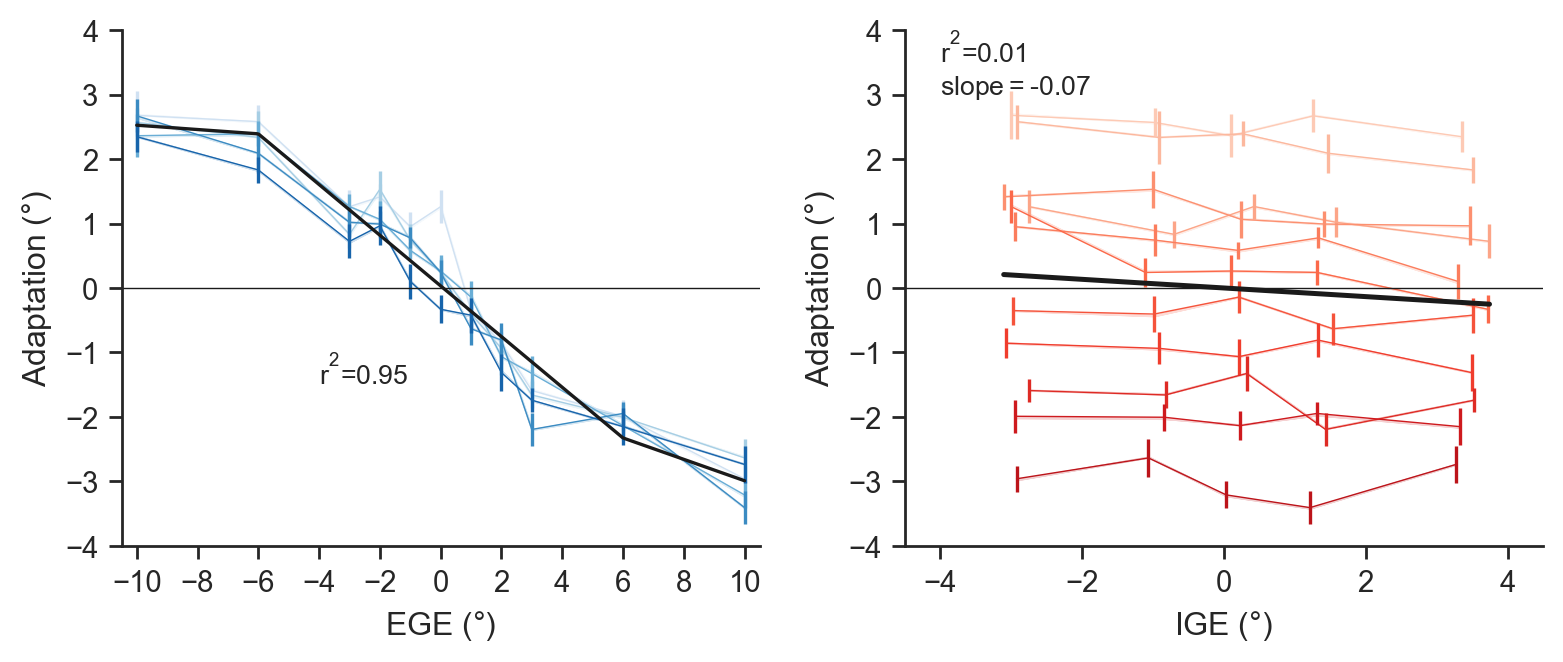

In [11]:
# Plot binned data
fig_rotation, y_fit, y_true, y_hat = plot_binned_data(rotation_binned, popn_rotation, "rotation", "beta_rotation_ege", "beta_rotation_ige")
fig_rotation.savefig("../figs/binned-adaptation.pdf")


In [12]:
# Compute r2 for breakpoint regression on binned data
vals_to_find_a = np.unique(popn_rotation["rotation"])
indices_a = np.searchsorted(x_fit, vals_to_find_a)
y_hat_a = np.repeat(y_fit[indices_a], 5)  # repeat 5 times bc there are 5 vals at each pert level
y_true_a = popn_rotation["adaptation"]

n = len(y_true_a) # Number of observations
p = 5          # Number of independent variables 

# Calculate the standard R-squared
r2 = r2_score(y_true_a, y_hat_a)

# Calculate the adjusted R-squared
adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)

print(f"R-squared: {r2}")
print(f"Adjusted R-squared: {adjusted_r2}")

R-squared: 0.9523692316354445
Adjusted R-squared: 0.9475089491492654


In [13]:
# Median RTs
temporal = test.groupby("SN")[["RT", "MT"]].median().reset_index()
print(temporal)
print(temporal["RT"].apply([np.mean, np.std]))
print(temporal["MT"].apply([np.mean, np.std]))

    SN        RT        MT
0    1  0.211776  0.339629
1    2  0.279688  0.371604
2    3  0.235719  0.427506
3    4  0.225567  0.391613
4    5  0.180272  0.388661
5    6  0.225722  0.347599
6    7  0.193791  0.459505
7    8  0.299687  0.359597
8    9  0.216431  0.355778
9   10  0.265700  0.395336
10  11  0.327437  0.395559
11  12  0.333639  0.371299
12  13  0.179363  0.315653
13  14  0.333594  0.467472
14  15  0.135847  0.327733
15  16  0.171799  0.383551
mean    0.238502
std     0.059998
Name: RT, dtype: float64
mean    0.381131
std     0.041540
Name: MT, dtype: float64


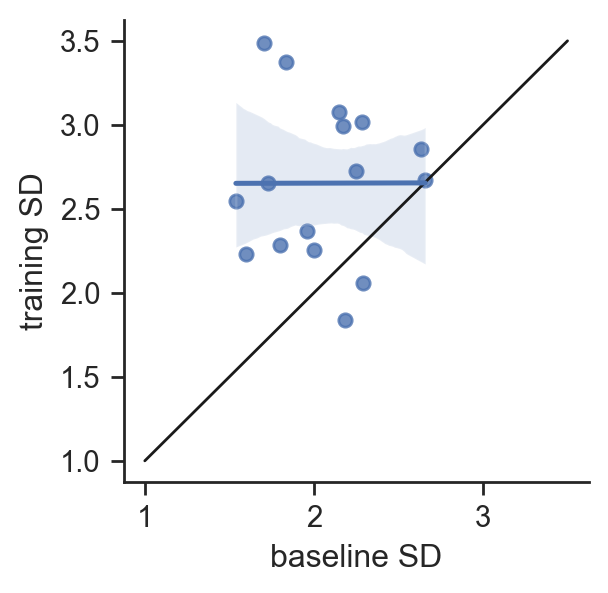

S14 had a baseline motor SD value of: 1.837, and training motor SD value of: 3.376
Max training SD: 3.486


In [26]:
# Check if motor variability increases during perturbation block
var = pd.DataFrame({
    "sigma_motor_bsl":pd.unique(test["sigma_motor_adapt"]),  # pd.unique does not sort
    "sigma_motor_train":np.array(sigma_motor_train), 
})

fig, ax = plt.subplots(figsize=(3, 3))
ax.plot([1, 3.5], [1, 3.5], "k", linewidth=1)
sns.regplot(data=var, x="sigma_motor_bsl", y="sigma_motor_train", ax=ax)
ax.set(xlabel="baseline SD", ylabel="training SD")
sns.despine()
plt.show()

# Check p14's motor variability (they were outlier in model fitting)
s14_bsl_sd = var.loc[13, "sigma_motor_bsl"]
s14_train_sd = var.loc[13, "sigma_motor_train"]
train_sd_max = np.max(var["sigma_motor_train"])
print(f"S14 had a baseline motor SD value of: {s14_bsl_sd:.3f}, and training motor SD value of: {s14_train_sd:.3f}")
print(f"Max training SD: {train_sd_max:.3f}")


---
## Statistics

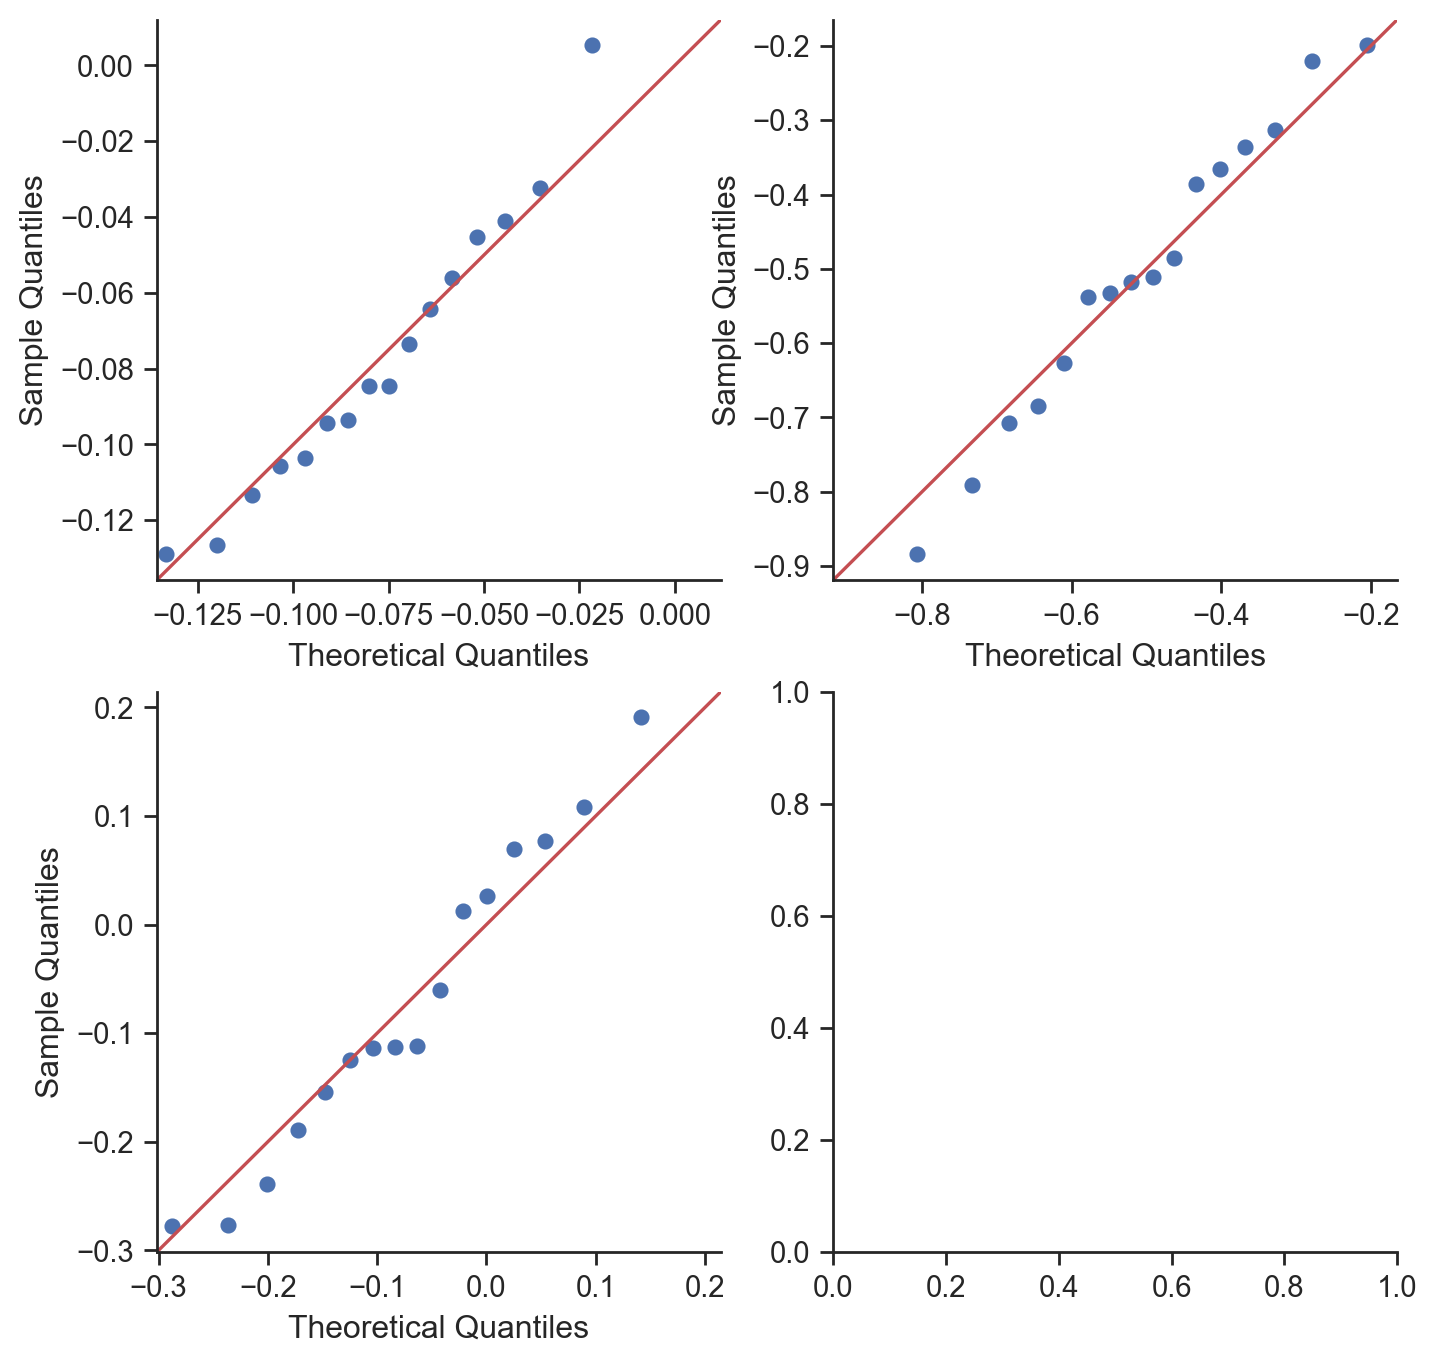

In [15]:
# Check all vars undergoing t-tests for normality
fig, axs = plt.subplots(2, 2, figsize=(8, 8))
diff_scores_vmr = beta_ege_6ege_uni - beta_ege_all_uni
sm.qqplot(diff_scores_vmr, loc=diff_scores_vmr.mean(), scale=diff_scores_vmr.std(), 
          line='45', ax=axs[0, 0])
sm.qqplot(beta_ege_1ege_bi, loc=beta_ege_1ege_bi.mean(), scale=beta_ege_1ege_bi.std(), 
          line='45', ax=axs[0, 1])
sm.qqplot(beta_ige_1ege_bi, loc=beta_ige_1ege_bi.mean(), scale=beta_ige_1ege_bi.std(), 
          line='45', ax=axs[1, 0])
plt.show()

In [16]:
# Baseline motor variability
res = bootstrap((test["sigma_motor_adapt"].unique(),), np.mean, method="percentile")
print(f"Mean and 95% CI of baseline motor variability: {test.sigma_motor_adapt.mean()},{[res.confidence_interval]}")

# Beta_EGE for EGEs of -6:6 only (bivariate)
res = bootstrap((beta_ege_6ege_uni,), np.mean, method="percentile")
print(f"Mean and 95% CI of univariate regression of [-6, 6] data: {beta_ege_6ege_uni.mean()},{res.confidence_interval}")

# Beta_EGE for all data (univariate)
res = bootstrap((beta_ege_all_uni,), np.mean, method="percentile")
print(f"Mean and 95% CI of univariate regression of all data: {beta_ege_all_uni.mean()},{res.confidence_interval}")

# Beta_EGE for EGEs of -6:+6 (univariate)
res = stats.ttest_rel(beta_ege_6ege_uni, beta_ege_all_uni)
print(f"Difference in slopes between [-6, 6] and all data: {res}")

# Beta_EGE for data only including EGEs of -1:+1 (bivariate)
res = bootstrap((beta_ege_1ege_bi,), np.mean, method="percentile")
print(f"Mean and 95% CI of EGE betas for 1deg data: {beta_ege_1ege_bi.mean()},{[res.confidence_interval]}")

# Beta_IGE for data only including EGEs of -1:+1 (bivariate)
res = bootstrap((beta_ige_1ege_bi,), np.mean, method="percentile")
print(f"Mean and 95% CI of IGE betas for 1deg data: {beta_ige_1ege_bi.mean()},{res.confidence_interval}")

# t-test against 0 for 1 deg Bivariate regression
res = stats.ttest_1samp(beta_ege_1ege_bi, popmean=0)
print(f"EGE betas for 1deg data versus Zero: {res}")

# t-test against 0 for 1 deg Bivariate regression
res = stats.ttest_1samp(beta_ige_1ege_bi, popmean=0)
print(f"IGE betas for 1deg data versus Zero: {res}")

# Beta_EGE for EGEs of -1:+1 (univariate)
res = bootstrap((beta_ege_1ege_uni,), np.mean, method="percentile")
print(f"Mean and 95% CI of univariate regression of EGEs from -1:+1: {beta_ege_1ege_uni.mean()},{res.confidence_interval}")

# Beta_IGE for IGEs of -1:+1 (univariate)
res = bootstrap((beta_ige_1ige_uni,), np.mean, method="percentile")
print(f"Mean and 95% CI of univariate regression of IGEs from -1:+1: {beta_ige_1ige_uni.mean()},{res.confidence_interval}")

Mean and 95% CI of baseline motor variability: 2.0491327383562274,[ConfidenceInterval(low=np.float64(1.895839436960328), high=np.float64(2.2141102745482586))]
Mean and 95% CI of univariate regression of [-6, 6] data: -0.3926050467862522,ConfidenceInterval(low=np.float64(-0.43441667565848535), high=np.float64(-0.34984553134995083))
Mean and 95% CI of univariate regression of all data: -0.314979709375393,ConfidenceInterval(low=np.float64(-0.3450647705217393), high=np.float64(-0.2844698935618704))
Difference in slopes between [-6, 6] and all data: TtestResult(statistic=np.float64(-8.428631855086364), pvalue=np.float64(4.5015998481543507e-07), df=np.int64(15))
Mean and 95% CI of EGE betas for 1deg data: -0.5059785808453945,[ConfidenceInterval(low=np.float64(-0.599661708788961), high=np.float64(-0.41467100841366367))]
Mean and 95% CI of IGE betas for 1deg data: -0.07343980917299205,ConfidenceInterval(low=np.float64(-0.13994127464549241), high=np.float64(-0.006363520096148735))
EGE betas for